# Mini traductor: entender el Transformer
Ejecuta las celdas en orden. Necesitas **PyTorch y Matplotlib** instalados en el entorno de Jupyter; para usar la RTX 4050, PyTorch debe ser una versión con CUDA ([instalación oficial](https://pytorch.org/get-started/locally/)). Si falta Matplotlib, puedes instalarlo con `%pip install matplotlib` en una celda temporal.

El objetivo es seguir la arquitectura del mismo Transformer pequeño mientras aprende de **frases reales español–inglés de Tatoeba**. Usaremos una muestra de 5000 pares cortos para mantener sencilla la práctica. Separaremos entrenamiento, validación y prueba para observar qué aprende y cómo responde a frases que no ha visto.

```text
Español → Embedding + posición → Encoder → memoria
                                             ↓
Inglés  → Embedding + posición → Decoder → Linear → siguiente palabra
                                      ↑
                                máscara causal
```

## 1. Importaciones y dispositivo
El modelo y cada lote usarán la GPU si CUDA está disponible. Fijamos una semilla para que la muestra y la división de los datos sean repetibles; los resultados numéricos pueden variar según el dispositivo.

In [1]:
import random
import re
import zipfile
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cuda


## 2. Frases de ejemplo
Ahora usamos un **dataset real de Tatoeba**, distribuido por [ManyThings/Anki](https://www.manythings.org/anki/). Descargamos la copia pública usada en el [ejemplo de traducción de Keras](https://keras.io/examples/nlp/neural_machine_translation_with_transformer/); no necesitamos instalar TensorFlow ni Keras. El ZIP contiene `spa.txt` y `_about.txt`, con información de origen y licencia CC BY 2.0.

La primera ejecución necesita internet; después reutiliza el ZIP guardado en `datos/`. Cada línea contiene inglés y español separados por una tabulación. Quitamos puntuación y pasamos a minúsculas, conservando tildes y apóstrofos.

Seleccionamos al azar **5000 pares con hasta 8 palabras por idioma**. Conservamos una referencia por frase española normalizada para evitar que esa misma entrada aparezca en conjuntos distintos. Dividimos **80 % entrenamiento, 10 % validación y 10 % prueba**. Las frases tienen longitudes diferentes, por lo que más adelante añadiremos padding.

In [2]:
NUM_PARES = 5000       # Puedes reducirlo si entrenas en CPU.
MAX_PALABRAS = 8
URL = "https://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip"
archivo = Path("datos/spa-eng.zip")
archivo.parent.mkdir(exist_ok=True)

if not archivo.exists():
    print("Descargando el dataset real...")
    with urlopen(URL, timeout=60) as respuesta:
        contenido = respuesta.read()
    archivo.write_bytes(contenido)

def normalizar(frase):
    frase = frase.lower().replace("’", "'")
    return " ".join(re.sub(r"[^a-záéíóúüñ' ]", " ", frase).split())

with zipfile.ZipFile(archivo) as zip_datos:
    lineas = zip_datos.read("spa-eng/spa.txt").decode("utf-8").splitlines()

por_espanol = {}
for linea in lineas:
    columnas = linea.split("\t")
    en, es = normalizar(columnas[0]), normalizar(columnas[1])
    if 1 <= len(es.split()) <= MAX_PALABRAS and 1 <= len(en.split()) <= MAX_PALABRAS:
        por_espanol.setdefault(es, en)

pares = list(por_espanol.items())
random.Random(42).shuffle(pares)
pares = pares[:NUM_PARES]

corte_train = int(0.8 * len(pares))
corte_val = int(0.9 * len(pares))
pares_train = pares[:corte_train]
pares_val = pares[corte_train:corte_val]
pares_prueba = pares[corte_val:]

print("Número de pares reales:", len(pares))
print("Entrenamiento / validación / prueba:",
      len(pares_train), len(pares_val), len(pares_prueba))
print(pares_train[:3])

Descargando el dataset real...
Número de pares reales: 5000
Entrenamiento / validación / prueba: 4000 500 500
[('estás demasiado borracho para conducir', "you're too drunk to drive"), ('entremos allí', "let's go in there"), ('china es más grande que japón', 'china is bigger than japan')]


## 3. Palabras → números
`split()` separa las palabras por espacios. Cada idioma tiene su propio vocabulario, creado **solo con entrenamiento**. Así, validación y prueba no aportan información al vocabulario.

Añadimos `<pad>` (relleno) y `<unk>` (palabra desconocida). En inglés también usamos `<ini>` (inicio) y `<fin>` (fin). `codificar` aplica la misma limpieza a las frases nuevas y convierte las palabras que no conoce en `<unk>`.

In [3]:
palabras_es = ["<pad>", "<unk>"] + sorted(
    {palabra for es, en in pares_train for palabra in es.split()}
)
palabras_en = ["<pad>", "<unk>", "<ini>", "<fin>"] + sorted(
    {palabra for es, en in pares_train for palabra in en.split()}
)

vocab_es = {palabra: i for i, palabra in enumerate(palabras_es)}
vocab_en = {palabra: i for i, palabra in enumerate(palabras_en)}

PAD_ES = vocab_es["<pad>"]
PAD_EN = vocab_en["<pad>"]
UNK_EN = vocab_en["<unk>"]
INICIO = vocab_en["<ini>"]
FINAL = vocab_en["<fin>"]

def codificar(frase, vocabulario):
    return [vocabulario.get(palabra, vocabulario["<unk>"])
            for palabra in normalizar(frase).split()]

print("Vocabularios español / inglés:", len(vocab_es), len(vocab_en))
print(pares_train[0][0], "→", codificar(pares_train[0][0], vocab_es))

Vocabularios español / inglés: 4119 2904
estás demasiado borracho para conducir → [1586, 1062, 461, 2785, 777]


## 4. Datos para el entrenamiento
El encoder recibe español. El decoder recibe inglés con un token de inicio y aprende a predecir la palabra siguiente.

```text
Entrada del encoder:  yo veo el gato       <pad> ...
Entrada del decoder:  <ini> i   see the cat <fin> <pad> ...
Objetivo:              i    see the cat <fin> <pad> <pad> ...
```

Durante el entrenamiento usamos las palabras correctas como entrada del decoder (**teacher forcing**). El desplazamiento se hace con `[:-1]` y `[1:]`.

`pad_sequence` completa las frases con `<pad>` para agruparlas. Las máscaras del modelo y la función de pérdida ignorarán ese relleno. Creamos un DataLoader para cada conjunto; **solo entrenamiento mezcla los lotes y actualiza los pesos**.

In [4]:
def crear_loader(datos, mezclar=False):
    src = pad_sequence(
        [torch.tensor(codificar(es, vocab_es)) for es, en in datos],
        batch_first=True, padding_value=PAD_ES,
    )
    tgt = pad_sequence(
        [torch.tensor([INICIO] + codificar(en, vocab_en) + [FINAL])
         for es, en in datos],
        batch_first=True, padding_value=PAD_EN,
    )
    return DataLoader(TensorDataset(src, tgt), batch_size=32, shuffle=mezclar)

loader = crear_loader(pares_train, mezclar=True)
loader_val = crear_loader(pares_val)
loader_prueba = crear_loader(pares_prueba)

src, tgt = loader.dataset.tensors
print("Encoder:", src[0].tolist())
print("Decoder:", [palabras_en[i] for i in tgt[0, :-1].tolist()])
print("Objetivo:", [palabras_en[i] for i in tgt[0, 1:].tolist()])

# Cobertura: cuántas palabras inglesas de validación conoce el vocabulario.
tokens_val = loader_val.dataset.tensors[1]
son_palabras = (tokens_val != PAD_EN) & (tokens_val != INICIO) & (tokens_val != FINAL)
conocidas = son_palabras & (tokens_val != UNK_EN)
print(f"Palabras inglesas conocidas en validación: {100 * conocidas.sum().item() / son_palabras.sum().item():.1f}%")

Encoder: [1586, 1062, 461, 2785, 777, 0, 0, 0]
Decoder: ['<ini>', "you're", 'too', 'drunk', 'to', 'drive', '<fin>', '<pad>', '<pad>']
Objetivo: ["you're", 'too', 'drunk', 'to', 'drive', '<fin>', '<pad>', '<pad>', '<pad>']
Palabras inglesas conocidas en validación: 93.1%


## 5. Máscara causal
El decoder puede consultar las palabras anteriores y la posición actual. Las posiciones futuras se bloquean.

En esta máscara booleana, **1 = bloqueado** y **0 = permitido**. Las filas consultan a las columnas.

tensor([[0, 1, 1, 1, 1],
        [0, 0, 1, 1, 1],
        [0, 0, 0, 1, 1],
        [0, 0, 0, 0, 1],
        [0, 0, 0, 0, 0]], device='cuda:0', dtype=torch.int32)


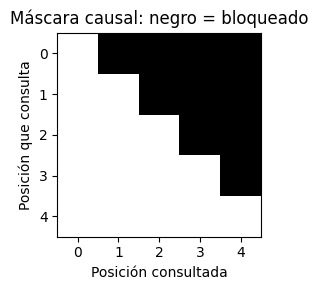

In [5]:
def mascara_causal(longitud):
    return torch.ones(longitud, longitud, dtype=torch.bool, device=device).triu(1)

print(mascara_causal(5).int())

plt.figure(figsize=(4, 3))
plt.imshow(mascara_causal(5).cpu().int(), cmap="Greys", vmin=0, vmax=1)
plt.xticks(range(5))
plt.yticks(range(5))
plt.xlabel("Posición consultada")
plt.ylabel("Posición que consulta")
plt.title("Máscara causal: negro = bloqueado")
plt.tight_layout()
plt.show()

## 6. Arquitectura del Transformer
Esta es la parte central del notebook.

- **Embedding:** convierte cada número en un vector de 64 valores.
- **Posición:** sumamos un vector aprendido para indicar el lugar de cada palabra.
- **Encoder:** procesa la frase española y produce la memoria.
- **Decoder:** procesa el inglés, aplica la máscara causal y consulta la memoria.
- **Linear:** convierte los vectores del decoder en puntuaciones para el vocabulario inglés.

Usamos un bloque de encoder y uno de decoder, con cuatro cabezas de atención. Dentro de esos bloques, `nn.Transformer` implementa:

```text
Encoder:
  Self-attention → Add & Norm → Feed-forward → Add & Norm

Decoder:
  Self-attention causal → Add & Norm
  Atención a la memoria del encoder → Add & Norm
  Feed-forward → Add & Norm
```

`batch_first=True` significa **[lote, número de palabras, dimensión]**. Las posiciones son embeddings aprendidos; el artículo original usa posiciones sinusoidales. [Documentación de nn.Transformer](https://docs.pytorch.org/docs/stable/generated/torch.nn.Transformer.html).

Para las frases reales, añadimos máscaras de padding al encoder, al decoder y a la atención sobre la memoria. La tabla de posiciones cubre `MAX_PALABRAS + 2`, incluyendo inicio y fin. Se mantienen las dimensiones, capas y cabezas del modelo original.

In [6]:
class MiniTraductor(nn.Module):
    def __init__(self):
        super().__init__()

        self.embedding_es = nn.Embedding(len(vocab_es), 64, padding_idx=PAD_ES)
        self.embedding_en = nn.Embedding(len(vocab_en), 64, padding_idx=PAD_EN)
        self.posicion = nn.Embedding(MAX_PALABRAS + 2, 64)

        self.transformer = nn.Transformer(
            d_model=64,
            nhead=4,
            num_encoder_layers=1,
            num_decoder_layers=1,
            dim_feedforward=128,
            batch_first=True,
        )

        self.linear = nn.Linear(64, len(vocab_en))

    def forward(self, src, tgt):
        # Ignorar el relleno en la atención.
        padding_src = src == PAD_ES
        padding_tgt = tgt == PAD_EN

        # 1. Palabras + posiciones
        posiciones_src = torch.arange(src.size(1), device=src.device)
        posiciones_tgt = torch.arange(tgt.size(1), device=tgt.device)

        src = self.embedding_es(src) + self.posicion(posiciones_src)
        tgt = self.embedding_en(tgt) + self.posicion(posiciones_tgt)

        # 2. El encoder construye la memoria del español.
        memoria = self.transformer.encoder(src, src_key_padding_mask=padding_src)

        # 3. El decoder consulta esa memoria sin mirar palabras futuras.
        salida = self.transformer.decoder(
            tgt,
            memoria,
            tgt_mask=mascara_causal(tgt.size(1)),
            tgt_key_padding_mask=padding_tgt,
            memory_key_padding_mask=padding_src,
        )

        # 4. Puntuaciones para cada palabra del vocabulario inglés.
        return self.linear(salida)

modelo = MiniTraductor().to(device)

## 7. Entrenamiento
`CrossEntropyLoss` compara las puntuaciones con la palabra correcta. Recibe las puntuaciones directamente, sin aplicar softmax antes. `ignore_index=PAD_EN` excluye el relleno.

`backward()` calcula los gradientes y `step()` actualiza los pesos. `reshape` agrupa las posiciones de todos los ejemplos del lote para calcular la pérdida.

En cada época mostramos tres métricas para **entrenamiento y validación**:

- **Pérdida (entropía cruzada):** cuanto más baja, mejor. Se promedia por token válido, no por lote.
- **Acierto por token (%):** porcentaje de siguientes tokens predichos correctamente, incluyendo `<fin>` y excluyendo `<pad>`. Un objetivo `<unk>` cuenta como error porque no recupera la palabra real.
- **Error por token (%):** `100 - acierto`. No es la tasa de error de palabras (WER).

Estas métricas usan **teacher forcing**: el modelo recibe el prefijo correcto. No representan el porcentaje de traducciones completas correctas; esa coincidencia se mide al final generando sin la referencia.

`modelo.eval()` y `torch.no_grad()` permiten validar sin actualizar pesos ni aplicar dropout. Usamos 30 épocas como punto de partida; puedes cambiar `EPOCAS`. Las gráficas ayudan a detectar sobreajuste: si la pérdida de entrenamiento baja pero la de validación sube, está memorizando más de lo que generaliza. Las métricas de entrenamiento se acumulan mientras cambian los pesos y hay dropout; las de validación se calculan al terminar la época.

Época 01 | Train: pérdida=3.611, acierto=38.6%, error=61.4% | Val: pérdida=4.211, acierto=37.7%, error=62.3%
Época 02 | Train: pérdida=3.353, acierto=40.7%, error=59.3% | Val: pérdida=4.228, acierto=38.7%, error=61.3%
Época 03 | Train: pérdida=3.139, acierto=42.3%, error=57.7% | Val: pérdida=4.192, acierto=39.7%, error=60.3%
Época 04 | Train: pérdida=2.931, acierto=44.3%, error=55.7% | Val: pérdida=4.166, acierto=40.2%, error=59.8%
Época 05 | Train: pérdida=2.730, acierto=46.3%, error=53.7% | Val: pérdida=4.190, acierto=41.0%, error=59.0%
Época 06 | Train: pérdida=2.533, acierto=48.6%, error=51.4% | Val: pérdida=4.187, acierto=41.7%, error=58.3%
Época 07 | Train: pérdida=2.337, acierto=51.1%, error=48.9% | Val: pérdida=4.231, acierto=41.9%, error=58.1%
Época 08 | Train: pérdida=2.165, acierto=53.9%, error=46.1% | Val: pérdida=4.240, acierto=42.7%, error=57.3%
Época 09 | Train: pérdida=1.990, acierto=56.8%, error=43.2% | Val: pérdida=4.285, acierto=42.6%, error=57.4%
Época 10 | Train: p

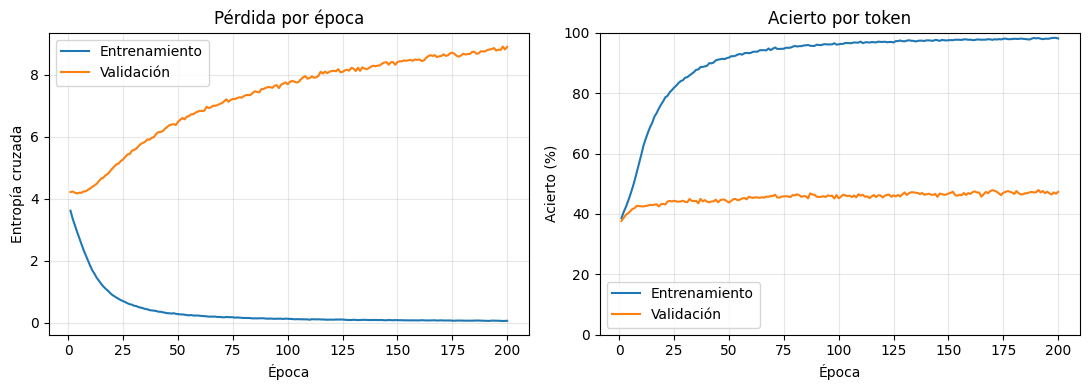

In [8]:
criterio = nn.CrossEntropyLoss(ignore_index=PAD_EN)
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)

def recorrer(datos, entrenar=False):
    modelo.train(entrenar)
    perdida_total = 0.0
    aciertos = 0
    total_tokens = 0

    with torch.set_grad_enabled(entrenar):
        for src, tgt in datos:
            src, tgt = src.to(device), tgt.to(device)
            entrada_decoder = tgt[:, :-1]
            objetivo = tgt[:, 1:]

            prediccion = modelo(src, entrada_decoder)
            perdida = criterio(
                prediccion.reshape(-1, len(vocab_en)),
                objetivo.reshape(-1),
            )

            if entrenar:
                optimizador.zero_grad()
                perdida.backward()
                optimizador.step()

            validos = objetivo != PAD_EN
            cantidad = validos.sum().item()
            correctos = (prediccion.argmax(-1) == objetivo) & validos & (objetivo != UNK_EN)
            aciertos += correctos.sum().item()
            total_tokens += cantidad
            perdida_total += perdida.item() * cantidad

    acierto = 100 * aciertos / total_tokens
    return perdida_total / total_tokens, acierto, 100 - acierto

EPOCAS = 200
historial = {"train": [], "val": []}

for epoca in range(1, EPOCAS + 1):
    train = recorrer(loader, entrenar=True)
    val = recorrer(loader_val)
    historial["train"].append(train)
    historial["val"].append(val)
    print(
        f"Época {epoca:02d} | "
        f"Train: pérdida={train[0]:.3f}, acierto={train[1]:.1f}%, error={train[2]:.1f}% | "
        f"Val: pérdida={val[0]:.3f}, acierto={val[1]:.1f}%, error={val[2]:.1f}%"
    )

epocas = range(1, EPOCAS + 1)
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for nombre, etiqueta in [("train", "Entrenamiento"), ("val", "Validación")]:
    ejes[0].plot(epocas, [m[0] for m in historial[nombre]], label=etiqueta)
    ejes[1].plot(epocas, [m[1] for m in historial[nombre]], label=etiqueta)

ejes[0].set(title="Pérdida por época", ylabel="Entropía cruzada")
ejes[1].set(title="Acierto por token", ylabel="Acierto (%)", ylim=(0, 100))
for eje in ejes:
    eje.set_xlabel("Época")
    eje.grid(alpha=0.3)
    eje.legend()
plt.tight_layout()
plt.show()

## 8. Generar una traducción
Ahora el decoder empieza solo con `<ini>`. Elegimos la palabra con mayor puntuación (`argmax`), la añadimos y repetimos. **No recibe las palabras de la traducción correcta.**

Terminamos cuando aparece `<fin>` o alcanzamos `MAX_PALABRAS + 1` pasos. Bloqueamos `<pad>` y `<ini>` porque no son palabras de la traducción; `<unk>` puede aparecer si el modelo no recupera una palabra conocida. Por claridad, ejecutamos el encoder y el decoder de nuevo en cada paso.

La entrada debe tener entre 1 y `MAX_PALABRAS` palabras tras la limpieza, igual que los ejemplos del dataset.

In [9]:
@torch.no_grad()
def traducir(frase):
    modelo.eval()
    codigos = codificar(frase, vocab_es)
    if not 1 <= len(codigos) <= MAX_PALABRAS:
        raise ValueError(f"Usa una frase de 1 a {MAX_PALABRAS} palabras.")

    src = torch.tensor([codigos], device=device)
    generados = [INICIO]

    for paso in range(MAX_PALABRAS + 1):
        tgt = torch.tensor([generados], device=device)
        prediccion = modelo(src, tgt)

        # Usamos la última posición para elegir la siguiente palabra.
        puntuaciones = prediccion[0, -1].clone()
        puntuaciones[PAD_EN] = -float("inf")
        puntuaciones[INICIO] = -float("inf")
        siguiente = puntuaciones.argmax().item()

        if siguiente == FINAL:
            break

        generados.append(siguiente)

    return " ".join(palabras_en[i] for i in generados[1:])

## 9. Ejemplos finales
Evaluamos **una vez en prueba**, después de entrenar. Este conjunto no se usa para actualizar pesos ni para seguir el aprendizaje por época. Mostramos pérdida, acierto y error por token con teacher forcing y, por separado, el porcentaje de **traducciones generadas que coinciden exactamente** con la referencia normalizada, sin teacher forcing.

La coincidencia exacta es estricta: una traducción válida con otras palabras puede contar como fallo. Se compara una sola referencia por frase y se ignoran mayúsculas y puntuación por la limpieza. Un acierto alto por token no garantiza una traducción completa correcta.

Los ejemplos son frases reales de prueba, no frases memorizadas del entrenamiento. El modelo sigue siendo pequeño y la muestra limitada: observa las curvas y las traducciones para entender sus avances y errores; los resultados pueden variar entre ejecuciones.

In [10]:
perdida_prueba, acierto_prueba, error_prueba = recorrer(loader_prueba)
print(
    f"Prueba (teacher forcing): pérdida={perdida_prueba:.3f}, "
    f"acierto por token={acierto_prueba:.1f}%, error por token={error_prueba:.1f}%"
)

traducciones = [traducir(es) for es, en in pares_prueba]
exactas = sum(predicha == en for predicha, (es, en) in zip(traducciones, pares_prueba))
acierto_exacto = 100 * exactas / len(pares_prueba)
print(f"Coincidencia exacta sin teacher forcing: {exactas}/{len(pares_prueba)} ({acierto_exacto:.1f}%)")
print(f"Traducciones sin coincidencia exacta: {100 - acierto_exacto:.1f}%")

for (es, en), predicha in list(zip(pares_prueba, traducciones))[:5]:
    print("\nEspañol:  ", es)
    print("Referencia:", en)
    print("Modelo:    ", predicha)
    print("Coincide:  ", "sí" if predicha == en else "no")

Prueba (teacher forcing): pérdida=8.673, acierto por token=48.2%, error por token=51.8%
Coincidencia exacta sin teacher forcing: 14/500 (2.8%)
Traducciones sin coincidencia exacta: 97.2%

Español:   es muy tarde el lunes
Referencia: is monday too late
Modelo:     it's very scared
Coincide:   no

Español:   soy muy olvidadizo
Referencia: i'm very forgetful
Modelo:     it's very disappointed in
Coincide:   no

Español:   querés un bolso
Referencia: do you want a bag
Modelo:     do you want a friend
Coincide:   no

Español:   no vamos a ir
Referencia: we're not going
Modelo:     we're not go to go
Coincide:   no

Español:   enséñame otro ejemplo
Referencia: show me another example
Modelo:     i want to help
Coincide:   no
